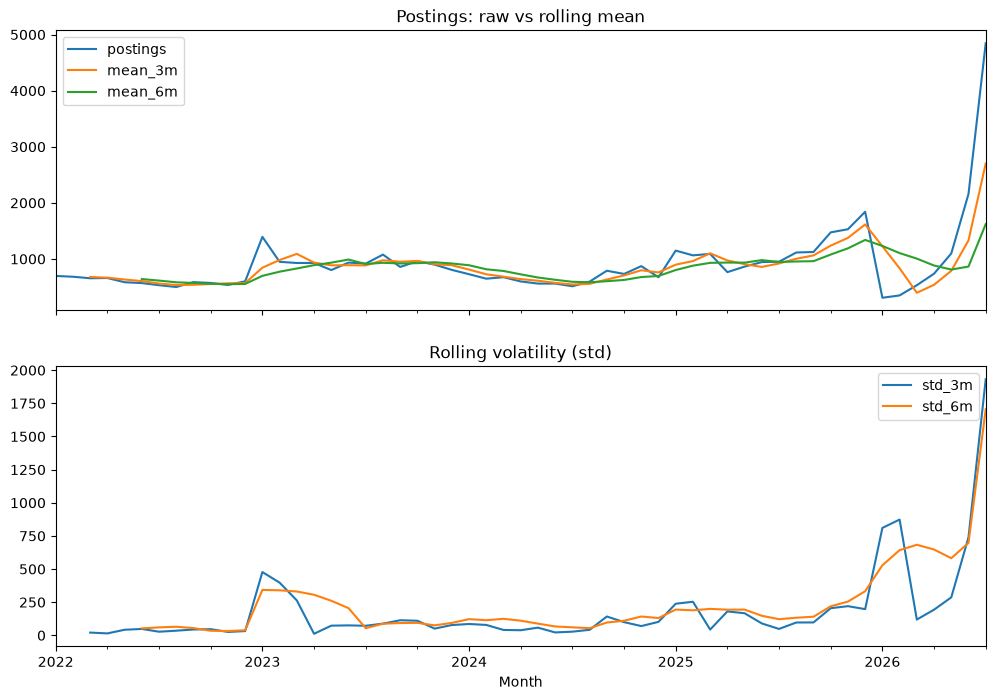

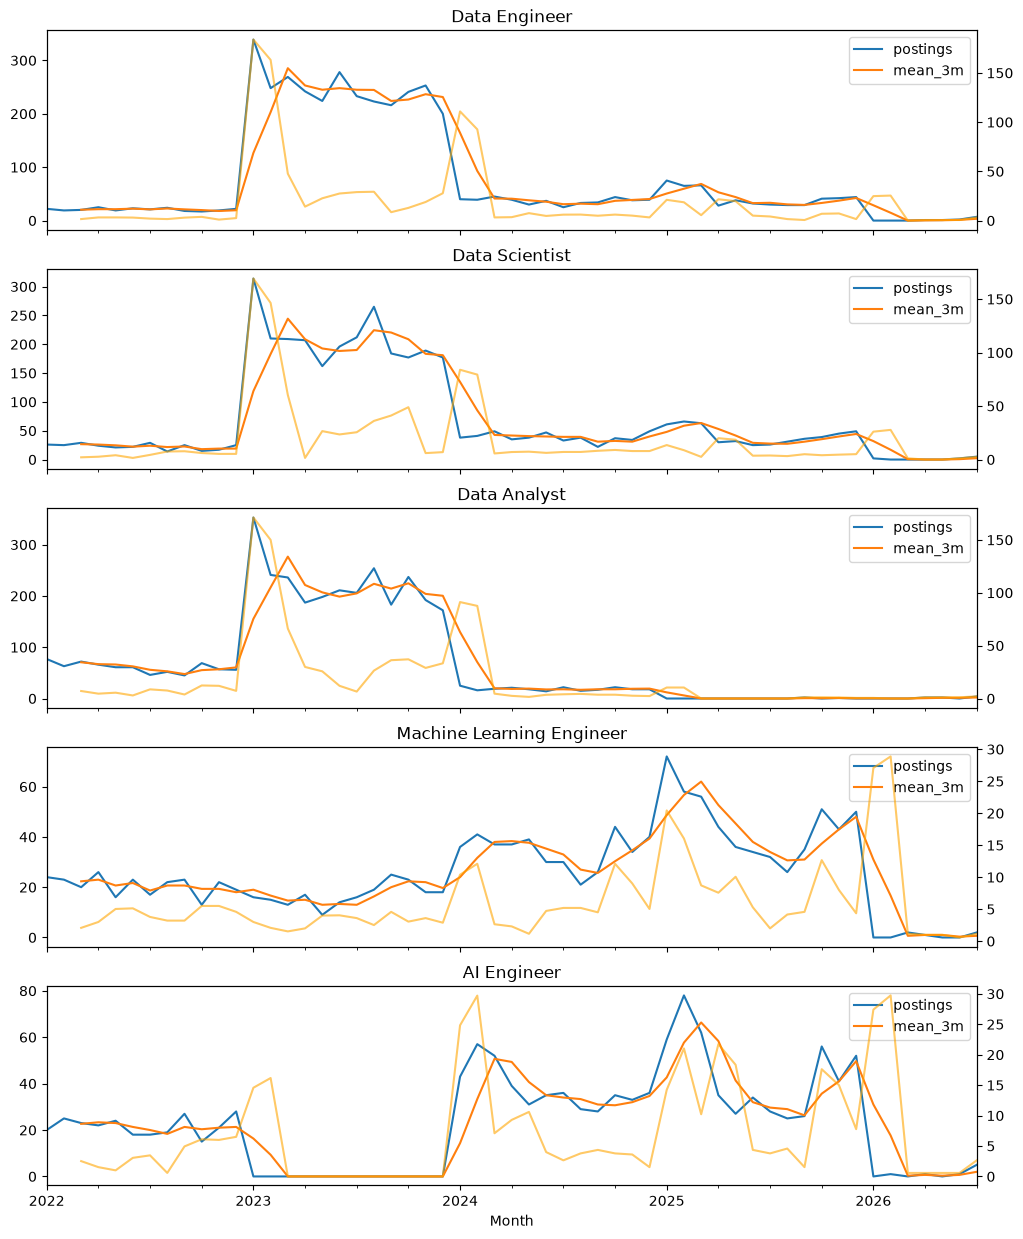

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Combined_Datasets_EDA.xls", parse_dates=["Posting_date"]).drop_duplicates()
df["Month"] = df["Posting_date"].dt.to_period("M").dt.to_timestamp()
df = df[(df["Month"] >= "2022-01") & (df["Month"] <= "2026-07")]

def roll(s, windows):
    out = s.rename("postings").to_frame()
    for w in windows:
        out[f"mean_{w}m"], out[f"std_{w}m"] = s.rolling(w).mean(), s.rolling(w).std()
    return out

# overall chart
ov = roll(df.groupby("Month").size(), (3, 6))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ov[["postings", "mean_3m", "mean_6m"]].plot(ax=a1, title="Postings: raw vs rolling mean")
ov[["std_3m", "std_6m"]].plot(ax=a2, title="Rolling volatility (std)")
plt.savefig("rolling_overall.png", dpi=150)

# top 5 titles chart
top = df["Job_Title"].value_counts().head(5).index
bt = df[df["Job_Title"].isin(top)].groupby(["Month", "Job_Title"]).size().unstack(fill_value=0)
fig, axes = plt.subplots(5, 1, figsize=(12, 15), sharex=True)
for ax, t in zip(axes, top):
    r = roll(bt[t], (3,))
    r[["postings", "mean_3m"]].plot(ax=ax, title=t)
    r["std_3m"].plot(ax=ax.twinx(), color="orange", alpha=.6)
plt.savefig("rolling_by_title.png", dpi=150)